In [2]:
from pathlib import Path
from collections import Counter
import csv
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Dataset and saved split
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

# 3. DeiT-Tiny model identifier
MODEL_NAME = "deit_tiny_patch16_224.fb_in1k"

# 4. Separate experiment folders
RESULTS_DIR = DATA_DIR / "results" / "deit_tiny"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 5. Apple GPU
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# 6. Verify saved dataset split
assert SPLIT_FILE.is_file(), "dataset_split.csv not found"

with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

split_counts = Counter(
    row["split"] for row in split_records
)

assert split_counts == {
    "train": 1402,
    "validation": 280,
    "test": 279
}, f"Unexpected dataset split: {split_counts}"


# 7. Verify DeiT-Tiny availability
available_models = timm.list_models(
    "*deit_tiny*",
    include_tags=True
)

print("Available DeiT-Tiny models:")
for name in available_models:
    print(" -", name)

assert MODEL_NAME in available_models, (
    f"{MODEL_NAME} not found. Available: {available_models}"
)

# 8. Print experiment configuration
print("\nEXPERIMENT: DeiT-Tiny")
print("-" * 45)

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("Device:", DEVICE)
print("Model:", MODEL_NAME)

print("\nDataset:")
for split in ["train", "validation", "test"]:
    print(f"  {split}: {split_counts[split]} images")

print("\nResults directory:", RESULTS_DIR)
print("Setup complete!")



Available DeiT-Tiny models:
 - deit_tiny_distilled_patch16_224.fb_in1k
 - deit_tiny_patch16_224.fb_in1k

EXPERIMENT: DeiT-Tiny
---------------------------------------------
PyTorch: 2.15.0
timm: 1.0.31
Device: mps
Model: deit_tiny_patch16_224.fb_in1k

Dataset:
  train: 1402 images
  validation: 280 images
  test: 279 images

Results directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/deit_tiny
Setup complete!


In [3]:

import torch
import timm

# 1. Load pretrained DeiT-Tiny
# Replace its original 1000-class head with 3 outputs
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=3
)

# 2. Move model to Apple GPU
model = model.to(DEVICE)
model.eval()

# 3. Inspect the architecture
print("Architecture: DeiT-Tiny")
print("Device:", DEVICE)

print("\nPATCH EMBEDDING")
print("Patch size:", model.patch_embed.patch_size)
print("Number of patches:", model.patch_embed.num_patches)
print("Embedding dimension:", model.num_features)

print("\nTRANSFORMER")
print("Transformer blocks:", len(model.blocks))
print("Classification token:", model.cls_token.shape)
print("Position embeddings:", model.pos_embed.shape)

# 4. Inspect the attention mechanism
first_block = model.blocks[0]

print("\nFIRST TRANSFORMER BLOCK")
print("Attention:", first_block.attn)
print("MLP:", first_block.mlp)

# 5. Inspect classification head
print("\nCLASSIFICATION HEAD")
print(model.head)

# 6. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"\nTotal parameters: {total_params:,}")

# 7. Test a forward pass
dummy_images = torch.randn(
    2, 3, 224, 224,
    device=DEVICE
)

with torch.inference_mode():
    outputs = model(dummy_images)

print("\nINPUT/OUTPUT")
print("Input shape:", dummy_images.shape)
print("Output shape:", outputs.shape)
print("First image logits:", outputs[0].cpu().tolist())


Architecture: DeiT-Tiny
Device: mps

PATCH EMBEDDING
Patch size: (16, 16)
Number of patches: 196
Embedding dimension: 192

TRANSFORMER
Transformer blocks: 12
Classification token: torch.Size([1, 1, 192])
Position embeddings: torch.Size([1, 197, 192])

FIRST TRANSFORMER BLOCK
Attention: Attention(
  (qkv): Linear(in_features=192, out_features=576, bias=True)
  (q_norm): Identity()
  (k_norm): Identity()
  (attn_drop): Dropout(p=0.0, inplace=False)
  (norm): Identity()
  (proj): Linear(in_features=192, out_features=192, bias=True)
  (proj_drop): Dropout(p=0.0, inplace=False)
)
MLP: Mlp(
  (fc1): Linear(in_features=192, out_features=768, bias=True)
  (act): GELU(approximate='none')
  (drop1): Dropout(p=0.0, inplace=False)
  (norm): Identity()
  (fc2): Linear(in_features=768, out_features=192, bias=True)
  (drop2): Dropout(p=0.0, inplace=False)
)

CLASSIFICATION HEAD
Linear(in_features=192, out_features=3, bias=True)

Total parameters: 5,524,995

INPUT/OUTPUT
Input shape: torch.Size([2, 3,

In [4]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class labels — same order as ResNet-18
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# 2. Reuse the exact saved dataset split
train_records = [
    r for r in split_records if r["split"] == "train"
]

val_records = [
    r for r in split_records if r["split"] == "validation"
]

test_records = [
    r for r in split_records if r["split"] == "test"
]

# 3. ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 4. Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 5. Validation/test transformations
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 6. Custom SEM Dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 7. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 8. Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 9. Verify image batches
batch_images, batch_labels = next(iter(train_loader))

print("DATASET VERIFICATION")
print("-" * 40)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nImage tensor shape:", batch_images.shape)
print("Label tensor shape:", batch_labels.shape)
print("First 10 labels:", batch_labels[:10].tolist())

print("\nData loading successful!")


DATASET VERIFICATION
----------------------------------------
Training samples: 1402
Validation samples: 280
Test samples: 279

Training batches: 88
Validation batches: 18
Test batches: 18

Image tensor shape: torch.Size([16, 3, 224, 224])
Label tensor shape: torch.Size([16])
First 10 labels: [0, 1, 1, 1, 0, 0, 0, 1, 1, 0]

Data loading successful!


In [5]:

import torch.nn as nn
from collections import Counter

# 1. Freeze all pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# 2. Unfreeze the classification head
for param in model.head.parameters():
    param.requires_grad = True

# 3. Count trainable and frozen parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("MODEL CONFIGURATION")
print("-" * 45)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

print("\nTrainable layers:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))

# 4. Calculate class weights from training data only
train_counts = Counter(
    row["label"] for row in train_records
)

num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[label])
        for label in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

print("\nCLASS WEIGHTS")
for label, weight in zip(CLASSES, class_weights):
    print(f"{label}: {weight.item():.4f}")

# 5. Weighted multiclass cross-entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 6. Optimizer — classification head only
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

optimizer = torch.optim.AdamW(
    model.head.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 7. Keep frozen transformer in evaluation mode
model.eval()

# 8. Verify optimizer only updates trainable parameters
optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

assert optimized_params == trainable_params

print("\nTRAINING CONFIGURATION")
print("-" * 45)
print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Optimized parameters:", optimized_params)

print("\nConfiguration verified!")


MODEL CONFIGURATION
---------------------------------------------
Total parameters: 5,524,995
Trainable parameters: 579
Frozen parameters: 5,524,416

Trainable layers:
head.weight (3, 192)
head.bias (3,)

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

TRAINING CONFIGURATION
---------------------------------------------
Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Optimized parameters: 579

Configuration verified!


In [6]:

import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score

# 1. Training configuration
NUM_EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

best_f1 = -1.0
best_epoch = 0

checkpoint_path = (
    CHECKPOINT_DIR / "deit_tiny_best.pth"
)

print("TRAINING DeiT-Tiny")
print("-" * 50)

# 2. Training loop
for epoch in range(NUM_EPOCHS):

    start_time = time.perf_counter()

    # Keep pretrained transformer in evaluation mode.
    # Train only the classification head.
    model.eval()
    model.head.train()

    train_loss_total = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update classification head
        optimizer.step()

        train_loss_total += loss.item() * labels.size(0)
        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # 3. Validation
    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_predictions = []
    all_labels = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # 4. Calculate validation metrics
    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 5. Record training history
    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_mixed_recall"].append(val_mixed_recall)
    history["epoch_time"].append(elapsed)

    # 6. Save best model based on Macro-F1
    if val_macro_f1 > best_f1:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save({
            "model_state_dict": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "epoch": best_epoch,
            "val_macro_f1": best_f1,
            "class_to_idx": class_to_idx,
            "model_name": MODEL_NAME
        }, checkpoint_path)

        status = "NEW BEST"
    else:
        status = ""

    # 7. Print results
    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}"
    )

# 8. Restore best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 9. Final summary
print("\nTRAINING COMPLETED")
print("-" * 50)

print("Best epoch:", best_epoch)
print(f"Best validation Macro-F1: {best_f1:.4f}")

print("\nREFERENCE COMPARISON")
print("ResNet-18 baseline Macro-F1:   0.9434")
print("ResNet-18 fine-tuned Macro-F1: 0.9525")
print(f"DeiT-Tiny Macro-F1:            {best_f1:.4f}")

print("\nAverage epoch time:",
      f"{np.mean(history['epoch_time']):.1f}s")

print("\nCheckpoint saved:", checkpoint_path)


TRAINING DeiT-Tiny
--------------------------------------------------
Epoch 01/10 | Train Loss: 0.5985 | Val Loss: 0.2569 | Accuracy: 0.936 | Macro-F1: 0.8551 | Mixed Recall: 0.714 | Time: 7.1s | NEW BEST
Epoch 02/10 | Train Loss: 0.3358 | Val Loss: 0.2018 | Accuracy: 0.943 | Macro-F1: 0.8684 | Mixed Recall: 0.762 | Time: 6.2s | NEW BEST
Epoch 03/10 | Train Loss: 0.2824 | Val Loss: 0.1923 | Accuracy: 0.936 | Macro-F1: 0.8568 | Mixed Recall: 0.762 | Time: 6.1s | 
Epoch 04/10 | Train Loss: 0.2607 | Val Loss: 0.1954 | Accuracy: 0.936 | Macro-F1: 0.8649 | Mixed Recall: 0.810 | Time: 5.8s | 
Epoch 05/10 | Train Loss: 0.2368 | Val Loss: 0.1519 | Accuracy: 0.954 | Macro-F1: 0.8873 | Mixed Recall: 0.714 | Time: 5.8s | NEW BEST
Epoch 06/10 | Train Loss: 0.2405 | Val Loss: 0.1721 | Accuracy: 0.946 | Macro-F1: 0.8864 | Mixed Recall: 0.857 | Time: 5.7s | 
Epoch 07/10 | Train Loss: 0.2124 | Val Loss: 0.1343 | Accuracy: 0.946 | Macro-F1: 0.8738 | Mixed Recall: 0.714 | Time: 5.7s | 
Epoch 08/10 | Tra

DeiT-Tiny — Best Head-Only Checkpoint
Best epoch: 5
Validation accuracy: 0.9536
Validation macro-F1: 0.8873

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Brittle     0.9669    1.0000    0.9832       117
     Ductile     0.9783    0.9507    0.9643       142
       Mixed     0.7143    0.7143    0.7143        21

    accuracy                         0.9536       280
   macro avg     0.8865    0.8883    0.8873       280
weighted avg     0.9537    0.9536    0.9534       280



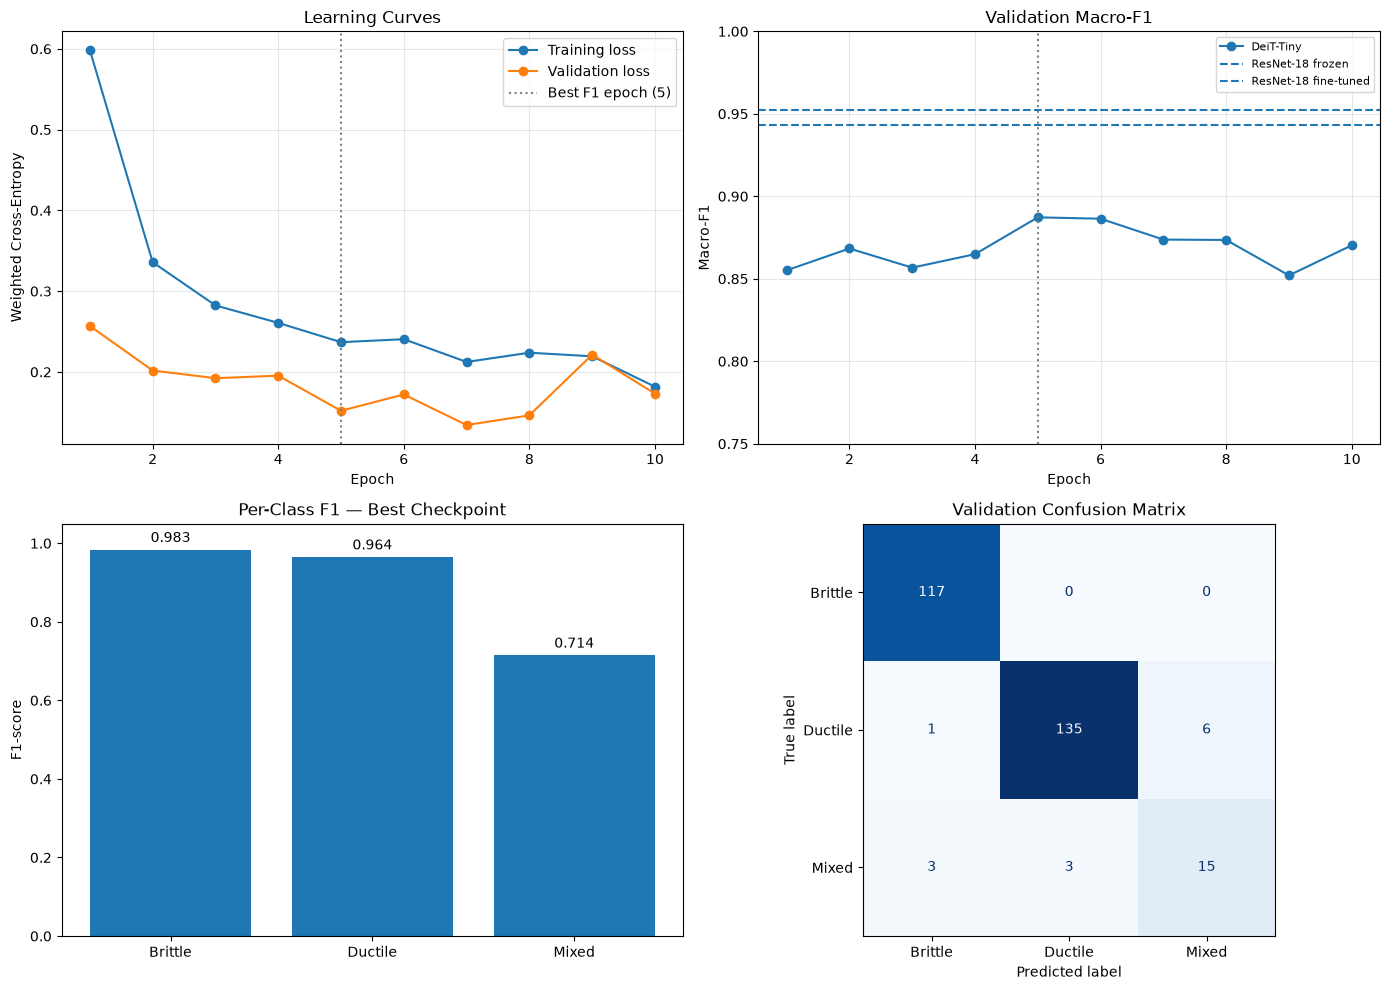


MISCLASSIFIED VALIDATION IMAGES
-----------------------------------------------------------------
304_H2_04_27.png | Actual: Ductile | Predicted: Mixed
304_H2_04_30.png | Actual: Ductile | Predicted: Mixed
316L_AR_04_7.png | Actual: Ductile | Predicted: Mixed
316L_AR_21_20.png | Actual: Ductile | Predicted: Mixed
316L_AR_23_13.png | Actual: Ductile | Predicted: Mixed
316L_AR_23_7.png | Actual: Ductile | Predicted: Brittle
mX65_AR_03_28.png | Actual: Ductile | Predicted: Mixed
304_H2_02_20.png | Actual: Mixed | Predicted: Brittle
304_H2_04_9.png | Actual: Mixed | Predicted: Brittle
mX65_H2_26_21.png | Actual: Mixed | Predicted: Brittle
mX65_H2_26_28.png | Actual: Mixed | Predicted: Ductile
mX65_H2_26_29.png | Actual: Mixed | Predicted: Ductile
mX65_H2_29_23.png | Actual: Mixed | Predicted: Ductile

Total errors: 13
Plot saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/deit_tiny/plots/deit_head_only_diagnostics.png


In [7]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

# 1. Evaluate the restored BEST DeiT-Tiny checkpoint
model.eval()

y_true = []
y_pred = []

with torch.inference_mode():
    for images, labels in val_loader:
        outputs = model(images.to(DEVICE))
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# Check that predictions align with validation records
assert len(y_true) == len(val_records)

assert all(
    CLASSES[y_true[i]] == val_records[i]["label"]
    for i in range(len(y_true))
)

# 2. Classification metrics
print("DeiT-Tiny — Best Head-Only Checkpoint")
print("=" * 55)

print(f"Best epoch: {best_epoch}")
print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Validation macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# 3. Per-class F1
class_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

# 4. Create diagnostic plots
epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot A: Learning curves
axes[0, 0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training loss"
)
axes[0, 0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation loss"
)
axes[0, 0].axvline(
    best_epoch,
    color="gray",
    linestyle=":",
    label=f"Best F1 epoch ({best_epoch})"
)
axes[0, 0].set_title("Learning Curves")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Weighted Cross-Entropy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Plot B: Macro-F1 vs ResNet baselines
axes[0, 1].plot(
    epochs, history["val_macro_f1"],
    marker="o", label="DeiT-Tiny"
)
axes[0, 1].axhline(
    0.9434,
    linestyle="--",
    label="ResNet-18 frozen"
)
axes[0, 1].axhline(
    0.9525,
    linestyle="--",
    label="ResNet-18 fine-tuned"
)
axes[0, 1].axvline(
    best_epoch,
    color="gray",
    linestyle=":"
)
axes[0, 1].set_title("Validation Macro-F1")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Macro-F1")
axes[0, 1].set_ylim(0.75, 1.0)
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.3)

# Plot C: Per-class F1
bars = axes[1, 0].bar(
    CLASSES,
    class_f1
)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_title("Per-Class F1 — Best Checkpoint")
axes[1, 0].set_ylabel("F1-score")

for bar, value in zip(bars, class_f1):
    axes[1, 0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

# Plot D: Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

display.plot(
    ax=axes[1, 1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1, 1].set_title("Validation Confusion Matrix")

plt.tight_layout()

plot_path = PLOTS_DIR / "deit_head_only_diagnostics.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 5. Identify incorrectly classified images
error_indices = [
    i for i, (actual, predicted) in enumerate(
        zip(y_true, y_pred)
    )
    if actual != predicted
]

print("\nMISCLASSIFIED VALIDATION IMAGES")
print("-" * 65)

for i in error_indices:
    row = val_records[i]
    print(
        f"{row['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Predicted: {CLASSES[y_pred[i]]}"
    )

print(f"\nTotal errors: {len(error_indices)}")
print("Plot saved:", plot_path)
